In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/stats_player_reg_2026.csv")

print(df.shape)
print(df.columns.tolist())

(1807, 148)
['player_id', 'player_name', 'player_display_name', 'position', 'position_group', 'headshot_url', 'season', 'season_type', 'recent_team', 'games', 'completions', 'attempts', 'passing_yards', 'passing_tds', 'passing_interceptions', 'sacks_suffered', 'sack_yards_lost', 'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards', 'passing_yards_after_catch', 'passing_first_downs', 'passing_epa', 'passing_cpoe', 'passing_2pt_conversions', 'pacr', 'passing_10', 'passing_16', 'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds', 'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs', 'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12', 'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards', 'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost', 'receiving_air_yards', 'receiving_yards_after_catch', 'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions', 'receiving_10', 'receiving_16', 'receiving_20', 

In [2]:
print(df["position"].value_counts())

position
LB     267
WR     229
CB     179
DT     150
RB     148
SAF    136
TE     127
DE     112
OT      97
G       79
QB      70
K       38
DB      37
C       36
P       34
LS      22
OLB     10
FS       9
FB       7
MLB      5
S        4
DL       4
NT       3
ILB      3
Name: count, dtype: int64


In [3]:
qb_df = df[df["position"] == "QB"].copy()

print(qb_df.shape)

(70, 148)


In [4]:
qb_df.head()

,player_id,player_name,player_display_name,position,position_group,headshot_url,season,season_type,recent_team,games,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,PIT,9,...,0,0,0,0,0,0,0,0,132.76,132.76
3,00-0026498,M.Stafford,Matthew Stafford,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,LA,10,...,0,0,0,0,0,0,0,0,162.62,162.62
9,00-0027973,A.Dalton,Andy Dalton,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,PHI,1,...,0,0,0,0,0,0,0,0,-2.00,-2.00
10,00-0028118,T.Taylor,Tyrod Taylor,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,GB,2,...,0,0,0,0,0,0,0,0,-0.08,-0.08
13,00-0028986,C.Keenum,Case Keenum,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,REG,CHI,2,...,0,0,0,0,0,0,0,0,25.20,25.20


In [5]:
for col in qb_df.columns:
    if "win" in col.lower():
        print(col)

In [6]:
for col in qb_df.columns:
    if "loss" in col.lower():
        print(col)

def_tackles_for_loss
def_tackles_for_loss_yards


In [7]:
qb_df = qb_df.sort_values(
    by="passing_yards",
    ascending=False
)

qb_df[
    [
        "player_display_name",
        "recent_team",
        "games",
        "passing_yards",
        "passing_tds",
        "passing_interceptions",
        "passing_epa",
        "passing_cpoe"
    ]
].head(15)

,player_display_name,recent_team,games,passing_yards,passing_tds,passing_interceptions,passing_epa,passing_cpoe
444,Jordan Love,GB,10,2838,20,7,55.813423,0.990165
514,Joe Burrow,CIN,9,2795,27,6,96.354470,10.534886
104,Dak Prescott,DAL,10,2724,21,6,63.602024,-0.133117
3,Matthew Stafford,LA,10,2623,19,10,46.007956,0.413497
14,Kirk Cousins,MIN,10,2547,22,9,54.036317,0.249250
1072,C.J. Stroud,HOU,9,2462,19,3,45.020180,0.853300
108,Jared Goff,DET,9,2437,18,4,64.310526,0.795071
1068,Bryce Young,CAR,9,2397,16,6,15.589684,0.214727
160,Patrick Mahomes,KC,9,2385,19,4,48.005213,1.911001
820,Brock Purdy,SF,9,2369,20,5,84.111358,5.431691


In [8]:
qb_df["completion_pct"] = (
    qb_df["completions"] /
    qb_df["attempts"]
) * 100

In [9]:
qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

In [10]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "completion_pct",
        "td_int_ratio"
    ]
].head()

,player_display_name,recent_team,completion_pct,td_int_ratio
444,Jordan Love,GB,63.043478,2.857143
514,Joe Burrow,CIN,74.705882,4.500000
104,Dak Prescott,DAL,64.082687,3.500000
3,Matthew Stafford,LA,66.666667,1.900000
14,Kirk Cousins,MIN,64.450867,2.444444


In [12]:
qb_df["completion_pct"] = (
    qb_df["completions"] /
    qb_df["attempts"]
) * 100

qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

qb_df["yards_per_attempt"] = (
    qb_df["passing_yards"] /
    qb_df["attempts"]
)

In [13]:
qb_df[
    [
        "player_display_name",
        "passing_tds",
        "passing_interceptions",
        "td_int_ratio"
    ]
].sort_values(
    by="td_int_ratio",
    ascending=False
).head(15)

,player_display_name,passing_tds,passing_interceptions,td_int_ratio
70,Marcus Mariota,4,0,inf
1516,Shedeur Sanders,2,0,inf
1461,DJ Uiagalelei,1,0,inf
327,Gardner Minshew,3,0,inf
1528,Jaxson Dart,3,0,inf
382,Drew Lock,7,0,inf
1072,C.J. Stroud,19,3,6.333333
257,Lamar Jackson,6,1,6.000000
1286,Jayden Daniels,10,2,5.000000
160,Patrick Mahomes,19,4,4.750000


In [14]:
metrics = [
    "completion_pct",
    "passing_yards",
    "passing_tds",
    "passing_interceptions",
    "passing_epa",
    "passing_cpoe",
    "yards_per_attempt",
    "td_int_ratio"
]

corr_matrix = qb_df[metrics].corr()

corr_matrix

,completion_pct,passing_yards,passing_tds,passing_interceptions,passing_epa,passing_cpoe,yards_per_attempt,td_int_ratio
completion_pct,1.000000,0.245590,0.239115,0.106799,0.252696,0.948622,0.634138,0.430136
passing_yards,0.245590,1.000000,0.947201,0.793830,0.571205,0.367768,0.458089,0.606244
passing_tds,0.239115,0.947201,1.000000,0.685820,0.736904,0.348735,0.444285,0.684449
passing_interceptions,0.106799,0.793830,0.685820,1.000000,0.129541,0.203226,0.255720,-0.035551
passing_epa,0.252696,0.571205,0.736904,0.129541,1.000000,0.306220,0.446870,0.673790
passing_cpoe,0.948622,0.367768,0.348735,0.203226,0.306220,1.000000,0.684812,0.517881
yards_per_attempt,0.634138,0.458089,0.444285,0.255720,0.446870,0.684812,1.000000,0.475434
td_int_ratio,0.430136,0.606244,0.684449,-0.035551,0.673790,0.517881,0.475434,1.000000


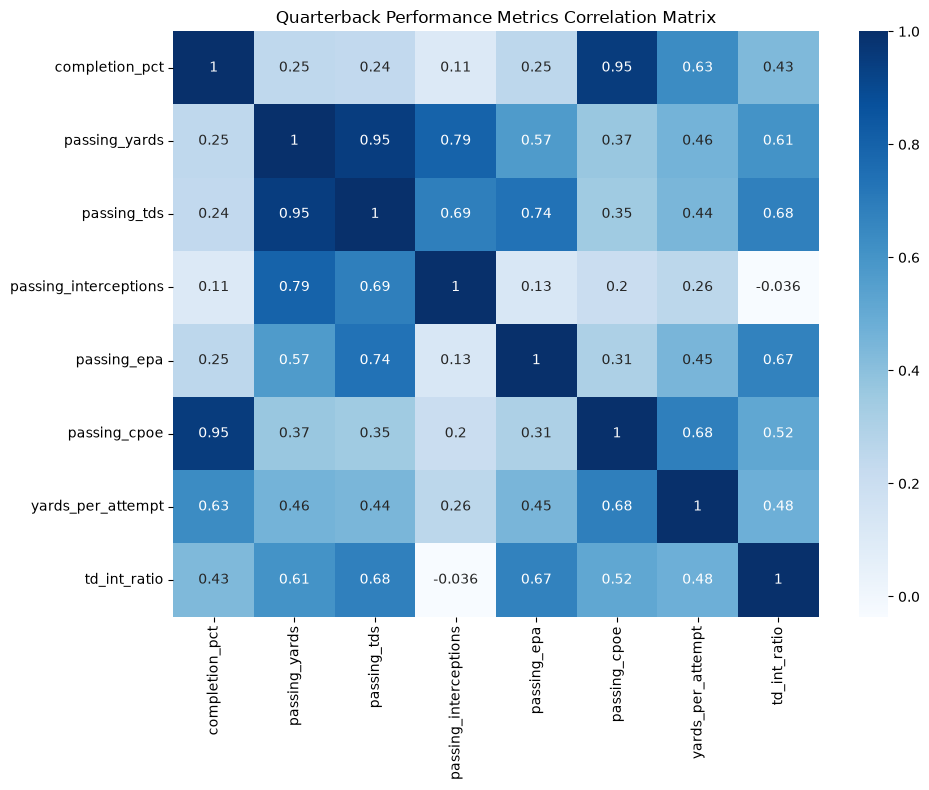

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Blues"
)

plt.title("Quarterback Performance Metrics Correlation Matrix")

plt.tight_layout()
plt.show()

In [16]:
import numpy as np

qb_df["td_int_ratio"] = (
    qb_df["passing_tds"] /
    qb_df["passing_interceptions"]
)

qb_df["td_int_ratio"] = (
    qb_df["td_int_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

In [17]:
qb_df[
    [
        "player_display_name",
        "passing_tds",
        "passing_interceptions",
        "td_int_ratio"
    ]
].sort_values(
    by="td_int_ratio",
    ascending=False
).head(15)

,player_display_name,passing_tds,passing_interceptions,td_int_ratio
1072,C.J. Stroud,19,3,6.333333
257,Lamar Jackson,6,1,6.000000
1286,Jayden Daniels,10,2,5.000000
160,Patrick Mahomes,19,4,4.750000
108,Jared Goff,18,4,4.500000
514,Joe Burrow,27,6,4.500000
630,Trevor Lawrence,21,5,4.200000
820,Brock Purdy,20,5,4.000000
29,Geno Smith,12,3,4.000000
403,Tyler Huntley,4,1,4.000000


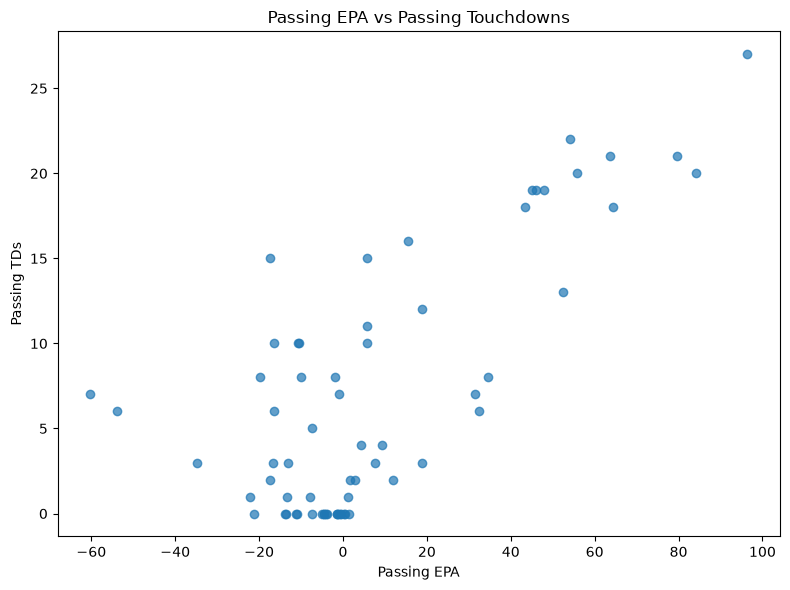

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    qb_df["passing_epa"],
    qb_df["passing_tds"],
    alpha=0.7
)

plt.xlabel("Passing EPA")
plt.ylabel("Passing TDs")
plt.title("Passing EPA vs Passing Touchdowns")

plt.tight_layout()
plt.show()

In [19]:
qb_df[
    [
        "player_display_name",
        "recent_team",
        "passing_epa",
        "passing_cpoe",
        "passing_tds",
        "passing_interceptions"
    ]
].sort_values(
    by="passing_epa",
    ascending=False
).head(15)

,player_display_name,recent_team,passing_epa,passing_cpoe,passing_tds,passing_interceptions
514,Joe Burrow,CIN,96.354470,10.534886,27,6
820,Brock Purdy,SF,84.111358,5.431691,20,5
630,Trevor Lawrence,JAX,79.744210,4.183893,21,5
108,Jared Goff,DET,64.310526,0.795071,18,4
104,Dak Prescott,DAL,63.602024,-0.133117,21,6
444,Jordan Love,GB,55.813423,0.990165,20,7
14,Kirk Cousins,MIN,54.036317,0.249250,22,9
277,Josh Allen,BUF,52.543438,2.747870,13,7
160,Patrick Mahomes,KC,48.005213,1.911001,19,4
3,Matthew Stafford,LA,46.007956,0.413497,19,10
